# 10 — Model CNN dan training (Bab 5.3–5.4)

Model: **CNN 1D** yang membaca waveform Z (potongan 120 s = 12,000 angka) dan 9 fitur konteks, lalu memprediksi 4 kelas. Training dijalankan **Spark TorchDistributor** dengan 5 proses PyTorch paralel (DDP), masing-masing membaca bagian datanya sendiri dari HDFS (`/datalake/ml/`).

| Komponen | File |
|---|---|
| Arsitektur, pembaca data, loop training | `src/cnn.py` |
| Peluncur training (Spark + TorchDistributor) | `src/train_cnn.py` |
| Halaman pemantau training (localhost) | `src/monitor.html` |

Training yang lama (±2 jam) dijalankan sebagai script di background, bukan di notebook. Notebook ini menampilkan arsitektur, pengaturan, dan hasilnya.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import cnn, ml_prep as mp
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Arsitektur (Bab 5.3)
Ukuran keluaran setiap lapisan dihitung dengan memasukkan satu contoh input kosong ke model.

In [2]:
model = cnn.CNN()
rows = []
def hook(name):
    return lambda m, i, o: rows.append((name, type(m).__name__, tuple(o.shape[1:]), sum(p.numel() for p in m.parameters())))
for name, m in [*[(f'wave.{i}', m) for i, m in enumerate(model.wave)], ('context', model.context), ('head', model.head)]:
    m.register_forward_hook(hook(name))
model.eval()(torch.zeros(1, 1, mp.CROP), torch.zeros(1, len(mp.CONTEXT_FEATURES)))
arch = pd.DataFrame(rows, columns=['bagian', 'lapisan', 'bentuk_keluaran', 'parameter'])
arch['lapisan'] = arch.lapisan.replace({'Sequential': 'Conv1d → BatchNorm → ReLU → MaxPool ÷4'})
arch.loc[arch.bagian == 'context', 'lapisan'] = 'Linear 9 → 16 → ReLU'
arch.loc[arch.bagian == 'head', 'lapisan'] = 'gabung 128 + 16 → Linear 64 → ReLU → Dropout 0.3 → Linear 4'
save_md(arch, 'a2_cnn_architecture', f'Arsitektur CNN ({sum(p.numel() for p in model.parameters()):,} parameter)')
print(f'total parameter: {sum(p.numel() for p in model.parameters()):,}')
arch

total parameter: 200,868


,bagian,lapisan,bentuk_keluaran,parameter
0,wave.0,Conv1d → BatchNorm → ReLU → MaxPool ÷4,"(16, 3000)",160
1,wave.1,Conv1d → BatchNorm → ReLU → MaxPool ÷4,"(32, 750)",3680
2,wave.2,Conv1d → BatchNorm → ReLU → MaxPool ÷4,"(64, 187)",14528
3,wave.3,Conv1d → BatchNorm → ReLU → MaxPool ÷4,"(128, 46)",57728
4,wave.4,Conv1d,"(128, 46)",114816
5,wave.5,BatchNorm1d,"(128, 46)",256
6,wave.6,ReLU,"(128, 46)",0
7,wave.7,AdaptiveAvgPool1d,"(128, 1)",0
8,wave.8,Flatten,"(128,)",0
9,context,Linear 9 → 16 → ReLU,"(16,)",160


- Empat blok konvolusi memadatkan 12,000 angka menjadi 46 langkah waktu × 128 pola. Lapisan awal mengenali pola kecil (getaran cepat/lambat), lapisan akhir pola besar (awal kejadian, durasi).
- **Global average pooling** merata-ratakan sepanjang waktu, sehingga hasilnya tidak bergantung pada posisi kejadian di dalam potongan.
- Cabang konteks (9 fitur waktu & sensor) digabung dengan ringkasan waveform sebelum lapisan keputusan.

## 2. Pengaturan training (Bab 5.4)
| Pengaturan | Nilai | Alasan singkat |
|---|---|---|
| Loss | cross-entropy berbobot (bobot kelas notebook 08) | Klasifikasi 4 kelas; kesalahan pada kelas kecil dihitung lebih berat |
| Optimizer | AdamW, learning rate 0.001, weight decay 0.0001 | Pilihan umum untuk CNN; langkah disesuaikan otomatis per bobot |
| Batch | 64 per proses × 5 proses = 320 per langkah | Muat di memori; gradien dirata-ratakan antar proses |
| Epoch | maksimal 15, early stopping patience 3 (macro-F1 validasi) | Berhenti saat tidak membaik; yang disimpan model terbaik |
| Learning rate | ReduceLROnPlateau (patience 1): dikali 0.5 setelah 2 epoch berturut-turut tidak membaik | Langkah lebih halus saat macet |
| Regularisasi | Dropout 0.3, BatchNorm, crop acak 120 s | Mencegah menghafal data latih |
| Paralelisme | TorchDistributor, 5 proses × 2 thread, backend gloo | 1 proses tidak bisa memakai semua core |
| Pengacakan | setiap proses membaca 6 file sekaligus, barisnya diacak bersama | Sebagian besar file Parquet didominasi satu kelas (lihat bagian 4) |
| Checkpoint | `last.pt` setiap akhir epoch, `best.pt` saat macro-F1 validasi naik | Training bisa dilanjutkan jika berhenti |
| Seed | 42 | Hasil bisa diulang |

## 3. Pilot: kecepatan dan cek model belajar
`python src/train_cnn.py --pilot` menjalankan 200 langkah training dengan 5 proses.

In [3]:
pilot = json.load(open(f'{OUT_TABLES}/a2_pilot.json'))
epoch_min = pilot['train_rows'] / pilot['rate'] / 60
pd.DataFrame({'nilai': {
    'proses × batch': f"{pilot['processes']} × {pilot['batch_per_process']}",
    'langkah': pilot['steps'],
    'waktu (detik)': round(pilot['seconds']),
    'kecepatan (rekaman/detik)': round(pilot['rate']),
    'loss 20 langkah pertama': round(pilot['loss_first'], 3),
    'loss 20 langkah terakhir': round(pilot['loss_last'], 3),
    'perkiraan 1 epoch latih (menit)': round(epoch_min, 1)}})

,nilai
proses × batch,5 × 64
langkah,200
waktu (detik),234
kecepatan (rekaman/detik),273
loss 20 langkah pertama,1.416
loss 20 langkah terakhir,0.586
perkiraan 1 epoch latih (menit),10.0


Satu proses saja hanya ±67 rekaman/detik dan tidak bertambah cepat dengan thread tambahan. Dengan 5 proses paralel kecepatannya naik ±4×, sehingga satu epoch (164,048 rekaman) selesai sekitar 10 menit. Loss turun tajam dalam 200 langkah, jadi model benar-benar belajar.

## 4. Menjalankan training
```bash
caffeinate -i .venv/bin/python src/train_cnn.py
python -m http.server 8765 --bind 127.0.0.1 --directory ~/pnwml-data/runs/cnn   # pemantau: http://127.0.0.1:8765/monitor.html
```
- Setiap akhir epoch disimpan `last.pt` (model, optimizer, scheduler, riwayat). Jika training berhenti, perintah yang sama melanjutkan dari epoch berikutnya.
- Kemajuan (epoch, langkah, loss, kecepatan, perkiraan sisa waktu) ditulis ke `progress.json` setiap 20 langkah dan ditampilkan di halaman pemantau, hanya bisa diakses dari komputer ini.
- Setelah selesai, model terbaik disalin ke `outputs/models/cnn_best.pt` dan HDFS `/datalake/ml/models/`.

**Masalah yang ditemukan saat training pertama.** Epoch 1 percobaan pertama menghasilkan train loss 0.56 tetapi validation loss 2.56 (macro-F1 0.35), selisih yang tidak wajar. Penyebabnya: Spark menulis setiap file Parquet dari partisi asal datanya, sehingga **20 dari 100 file latih hanya berisi satu kelas dan 66 file ±90% satu kelas**. Karena data dibaca file per file, hampir setiap batch berisi satu kelas saja. BatchNorm lalu belajar statistik per kelas yang tidak berlaku saat evaluasi. Perbaikan: setiap proses membaca 6 file sekaligus dan mengacak semua barisnya sebelum dibagi menjadi batch. Uji singkat setelah perbaikan: validation loss 0.64 (sejalan dengan train loss). Training lalu diulang dari awal; percobaan pertama disimpan terpisah dan tidak dipakai.

## 5. Hasil training

In [4]:
hist = pd.DataFrame(json.load(open(f'{OUT_TABLES}/a2_training_history.json')))
best = hist.loc[hist.val_macro_f1.idxmax()]
show = hist[['epoch', 'train_loss', 'val_loss', 'val_macro_f1', 'val_acc', *[f'f1_{c}' for c in CLASSES], 'lr', 'seconds']].copy()
show['minutes'] = (show.pop('seconds') / 60).round(1)
save_md(show.round(4), 'a2_training_history', 'Riwayat training per epoch (validasi = 35,078 rekaman)')
print(f"epoch terbaik: {int(best.epoch)}, macro-F1 validasi {best.val_macro_f1:.4f}; "
      f"{len(hist)} epoch, total {hist.seconds.sum() / 3600:.2f} jam")
show.round(4)

epoch terbaik: 9, macro-F1 validasi 0.8572; 12 epoch, total 2.44 jam


,epoch,train_loss,val_loss,val_macro_f1,val_acc,f1_earthquake,f1_explosion,f1_surface_event,f1_noise,lr,minutes
0,1,0.5943,0.6806,0.6435,0.7246,0.7832,0.4805,0.5725,0.7378,0.0010,11.7
1,2,0.4353,1.4619,0.5675,0.8120,0.8708,0.5493,0.0000,0.8501,0.0010,11.7
2,3,0.3807,0.4958,0.7369,0.8351,0.8883,0.5437,0.6436,0.8722,0.0010,13.9
3,4,0.3355,0.3665,0.7818,0.8669,0.9084,0.6230,0.7046,0.8911,0.0010,12.3
4,5,0.3053,0.3189,0.7421,0.8396,0.8798,0.6244,0.5635,0.9007,0.0010,12.1
5,6,0.2561,0.3455,0.8139,0.8882,0.9255,0.6736,0.7673,0.8894,0.0010,12.5
6,7,0.2605,0.3049,0.8166,0.8844,0.9156,0.6941,0.7603,0.8963,0.0010,12.3
7,8,0.2390,0.3706,0.8437,0.9084,0.9356,0.7735,0.7682,0.8975,0.0010,12.2
8,9,0.2341,0.3133,0.8572,0.9235,0.9491,0.7587,0.7902,0.9307,0.0010,12.1
9,10,0.2286,0.5091,0.8035,0.8991,0.9325,0.7170,0.6582,0.9062,0.0010,12.4


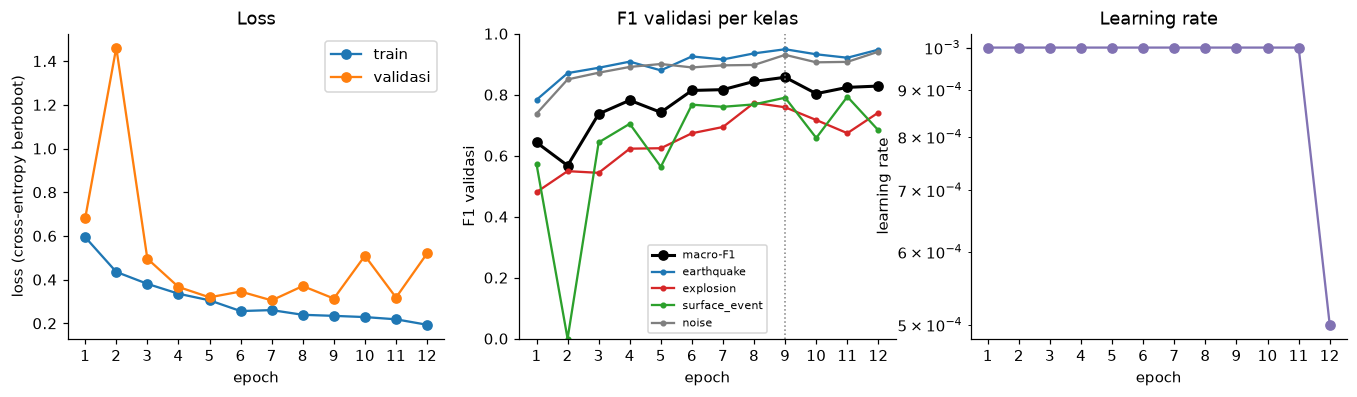

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(hist.epoch, hist.train_loss, 'o-', label='train')
axes[0].plot(hist.epoch, hist.val_loss, 'o-', label='validasi')
axes[0].set(xlabel='epoch', ylabel='loss (cross-entropy berbobot)', title='Loss'); axes[0].legend()
axes[1].plot(hist.epoch, hist.val_macro_f1, 'o-', color='k', lw=2, label='macro-F1')
for c in CLASSES:
    axes[1].plot(hist.epoch, hist[f'f1_{c}'], '.-', color=COLORS[c], label=c)
axes[1].axvline(best.epoch, color='grey', ls=':', lw=1)
axes[1].set(xlabel='epoch', ylabel='F1 validasi', title='F1 validasi per kelas', ylim=(0, 1)); axes[1].legend(fontsize=7)
axes[2].plot(hist.epoch, hist.lr, 'o-', color='#8172b3')
axes[2].set(xlabel='epoch', ylabel='learning rate', title='Learning rate', yscale='log')
for ax in axes:
    ax.set_xticks(hist.epoch)
save_fig('a2_learning_curves'); plt.show()

- **Training berhenti di epoch 12** (early stopping: 3 epoch tanpa perbaikan setelah epoch 9). Model yang dipakai adalah **epoch 9: macro-F1 validasi 0.857, accuracy 0.924**. Total waktu 147 menit (±12 menit per epoch).
- **Train loss turun terus** (0.59 → 0.19). **Macro-F1 validasi naik** dari 0.64 (epoch 1) ke 0.86 (epoch 9), lalu naik-turun di 0.80–0.83 tanpa melampaui epoch 9.
- **Validation loss naik-turun** (0.30–0.52) sementara train loss terus turun. Ini tanda model mulai terlalu menyesuaikan diri dengan data latih setelah epoch 9, sehingga berhenti di sini tepat.
- **Epoch 2** adalah lonjakan sementara: F1 surface_event jatuh ke 0 (val loss 1.46), lalu pulih di epoch 3. Learning rate 0.001 membuat model sempat "melupakan" kelas terkecil; model terbaik tidak terpengaruh karena yang disimpan hanya epoch dengan macro-F1 tertinggi.
- **Kelas tersulit: explosion** (F1 terbaik 0.76), diikuti surface_event (0.79). Earthquake (0.95) dan noise (0.93) paling mudah.
- Learning rate baru diturunkan ke 0.0005 setelah epoch 10–11 (dua epoch berturut-turut tidak membaik), jadi efeknya hanya terlihat di epoch 12.

## 6. Log training

In [6]:
print(open(f'{OUT_TABLES}/a2_training_log.txt').read())

2026-10-11 09:31:43  start: 5 processes x 2 threads, batch 64/process, 510 steps/epoch, 164,048 train rows, 35,078 val rows
2026-10-11 09:35:39  epoch 1 step 200/510  loss 0.7715  271 rec/s
2026-10-11 09:39:36  epoch 1 step 400/510  loss 0.6351  271 rec/s
2026-10-11 09:43:27  epoch 1 done in 11.7 min  train_loss 0.5943  val_loss 0.6806  val_macro_f1 0.6435  * best
2026-10-11 09:47:19  epoch 2 step 200/510  loss 0.4967  276 rec/s
2026-10-11 09:51:12  epoch 2 step 400/510  loss 0.4615  275 rec/s
2026-10-11 09:55:08  epoch 2 done in 11.7 min  train_loss 0.4353  val_loss 1.4619  val_macro_f1 0.5675
2026-10-11 09:59:07  epoch 3 step 200/510  loss 0.4269  268 rec/s
2026-10-11 10:04:32  epoch 3 step 400/510  loss 0.3963  227 rec/s
2026-10-11 10:09:03  epoch 3 done in 13.9 min  train_loss 0.3807  val_loss 0.4958  val_macro_f1 0.7369  * best
2026-10-11 10:13:27  epoch 4 step 200/510  loss 0.3324  242 rec/s
2026-10-11 10:17:32  epoch 4 step 400/510  loss 0.3332  251 rec/s
2026-10-11 10:21:21  ep